<center><h1>Lan_Yangrong_HW6</h1></center>

**Name:** Yangrong Lan  
**GitHub Username:** CallistoAma  
**USC ID:** 5561147067

## 1. Tree-Based Methods

### Imports and reproducibility

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline as SkPipeline
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 552
N_JOBS = -1
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.4g}")

### (a) Download the APS Failure data

In [2]:
DATA_DIR = Path("source") / "Homework 6 Data"
TRAIN_PATH = DATA_DIR / "aps_failure_training_set.csv"
TEST_PATH = DATA_DIR / "aps_failure_test_set.csv"

def read_aps(path):
    # The supplied CSVs begin with a license block. Find the actual header robustly.
    with path.open("r", encoding="utf-8", errors="replace") as handle:
        header_row = next(i for i, line in enumerate(handle) if line.startswith("class,"))
    return pd.read_csv(path, skiprows=header_row, na_values="na", low_memory=False)

train_df = read_aps(TRAIN_PATH)
test_df = read_aps(TEST_PATH)
feature_names = train_df.columns.drop("class").tolist()
X_train_raw = train_df[feature_names]
X_test_raw = test_df[feature_names]
y_train = train_df["class"].map({"neg": 0, "pos": 1}).astype(int)
y_test = test_df["class"].map({"neg": 0, "pos": 1}).astype(int)

print("Training shape:", train_df.shape, "Test shape:", test_df.shape)
print("Number of numeric features:", len(feature_names))
display(train_df.head(3))

Training shape: (60000, 171) Test shape: (16000, 171)
Number of numeric features: 170


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.131e+09,280,0,0,0,0,0,...,1.241e+06,4.934e+05,7.21e+05,4.698e+05,3.392e+05,1.58e+05,7.322e+04,0,0,0
1,neg,33058,NaN,0,NaN,0,0,0,0,0,...,4.214e+05,1.781e+05,2.933e+05,2.454e+05,1.337e+05,8.114e+04,9.758e+04,"1,500",0,0
2,neg,41040,NaN,228,100,0,0,0,0,0,...,2.774e+05,1.598e+05,4.24e+05,4.096e+05,3.207e+05,1.58e+05,9.513e+04,514,0,0


### (b) Data Preparation

#### (i) Missing-value techniques and selected approach

Common approaches include deleting rows or columns, constant imputation, mean/median/mode imputation, k-nearest-neighbor imputation, regression or iterative imputation, and multiple imputation. Deletion is unattractive here because missingness is widespread and would discard substantial information.

I use **median imputation**. It is computationally practical for 60,000 observations and is more robust than the mean for the strongly skewed sensor variables. The imputer is fit on training data only and then applied to the test data. For cross-validation, the imputer is placed inside the pipeline so each validation fold remains unseen during preprocessing.

In [3]:
missing_summary = pd.DataFrame({
    "train_missing": X_train_raw.isna().sum(),
    "train_missing_pct": X_train_raw.isna().mean() * 100,
    "test_missing": X_test_raw.isna().sum(),
    "test_missing_pct": X_test_raw.isna().mean() * 100,
}).sort_values("train_missing_pct", ascending=False)
display(missing_summary.head(15).style.format({"train_missing_pct":"{:.2f}%", "test_missing_pct":"{:.2f}%"}))

imputer = SimpleImputer(strategy="median", keep_empty_features=True)
X_train = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=feature_names, index=X_train_raw.index)
X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=feature_names, index=X_test_raw.index)
print("Remaining missing values:", int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum()))

,train_missing,train_missing_pct,test_missing,test_missing_pct
br_000,49264,82.11%,13129,82.06%
bq_000,48722,81.20%,12981,81.13%
bp_000,47740,79.57%,12721,79.51%
bo_000,46333,77.22%,12376,77.35%
ab_000,46329,77.22%,12363,77.27%
cr_000,46329,77.22%,12363,77.27%
bn_000,44009,73.35%,11713,73.21%
bm_000,39549,65.92%,10546,65.91%
bl_000,27277,45.46%,7226,45.16%
bk_000,23034,38.39%,6094,38.09%


Remaining missing values: 0 0


#### (ii) Coefficient of variation

In [4]:
# CV = sample standard deviation / mean. APS attributes are non-negative; near-zero
# means are treated as undefined to avoid unstable division.
means = X_train.mean(axis=0)
sample_stds = X_train.std(axis=0, ddof=1)
cv_values = sample_stds.div(means.mask(np.isclose(means, 0)))
cv_table = pd.DataFrame({"mean": means, "sample_std": sample_stds, "CV": cv_values})
cv_table = cv_table.sort_values("CV", ascending=False)

# The question asks for the CV of every feature, so show all 170 rows rather than a preview.
with pd.option_context("display.max_rows", None):
    display(cv_table[["mean", "sample_std", "CV"]].style.format("{:.5g}"))
print(f"Displayed coefficients of variation for all {len(cv_table)} features.")

,mean,sample_std,CV
cf_000,1.4311e+05,3.5045e+07,244.89
co_000,1.4333e+05,3.5045e+07,244.51
ad_000,1.4344e+05,3.5045e+07,244.32
cs_009,770.51,1.8333e+05,237.93
dh_000,4392.6,5.4124e+05,123.22
dj_000,37.271,4379.2,117.49
ag_000,219.16,20364,92.918
as_000,125.41,10952,87.332
ay_009,1149.6,97412,84.734
ak_000,907.66,72999,80.425


Displayed coefficients of variation for all 170 features.


#### (iii) Correlation matrix

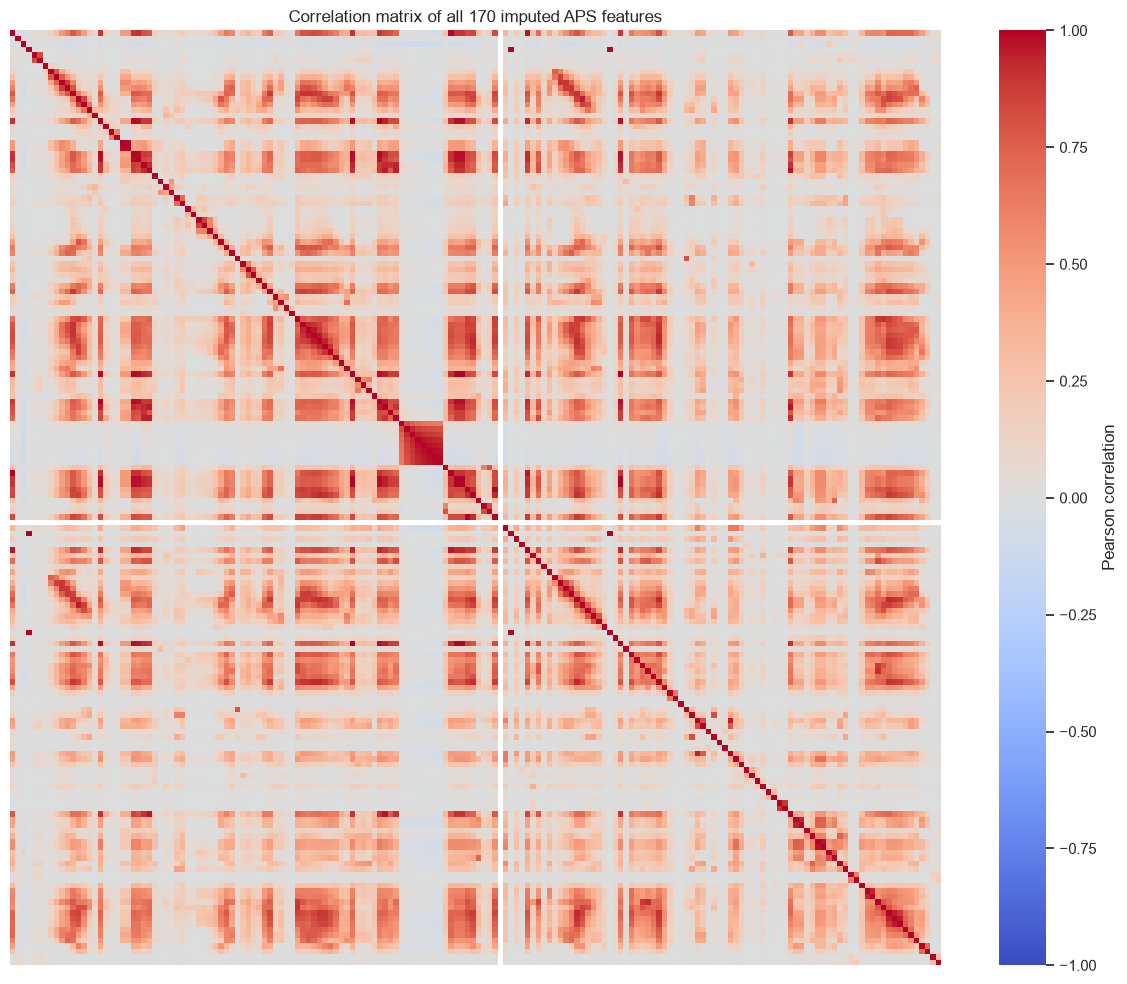

,feature_1,feature_2,correlation
0,bv_000,cq_000,1.0000
1,bu_000,cq_000,1.0000
2,bu_000,bv_000,1.0000
3,cf_000,co_000,1.0000
4,ad_000,cf_000,1.0000
5,ad_000,co_000,1.0000
6,aa_000,bt_000,0.9988
7,ah_000,bg_000,0.9977
8,bb_000,bv_000,0.9963
9,bb_000,bu_000,0.9963


In [5]:
corr = X_train.corr()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            xticklabels=False, yticklabels=False, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation matrix of all 170 imputed APS features")
plt.tight_layout(); plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
strongest = upper.abs().sort_values(ascending=False).head(10).index
strong_pairs = pd.DataFrame([
    {"feature_1": a, "feature_2": b, "correlation": corr.loc[a,b]} for a,b in strongest
])
display(strong_pairs.style.format({"correlation":"{:.4f}"}))

#### (iv) Scatter plots and box plots for the highest-CV features

sqrt(170) = 13.038; using 13 features:
['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


,CV,negative median log1p,positive median log1p,standardized mean difference,orientation-adjusted univariate AUC,direction for positive class,max absolute correlation with another feature
feature,,,,,,,
cf_000,244.888,1.099,1.099,0.766,0.584,higher,1.000
co_000,244.507,2.197,2.197,0.354,0.598,higher,1.000
ad_000,244.323,4.844,4.844,0.377,0.588,higher,1.000
cs_009,237.931,0.000,0.000,0.105,0.502,higher,0.067
dh_000,123.216,0.000,0.000,0.194,0.506,higher,0.201
dj_000,117.494,0.000,0.000,-0.024,0.501,lower,0.315
ag_000,92.918,0.000,0.000,1.484,0.548,higher,0.165
as_000,87.332,0.000,0.000,0.361,0.503,higher,0.511
ay_009,84.734,0.000,0.000,2.456,0.601,higher,0.789


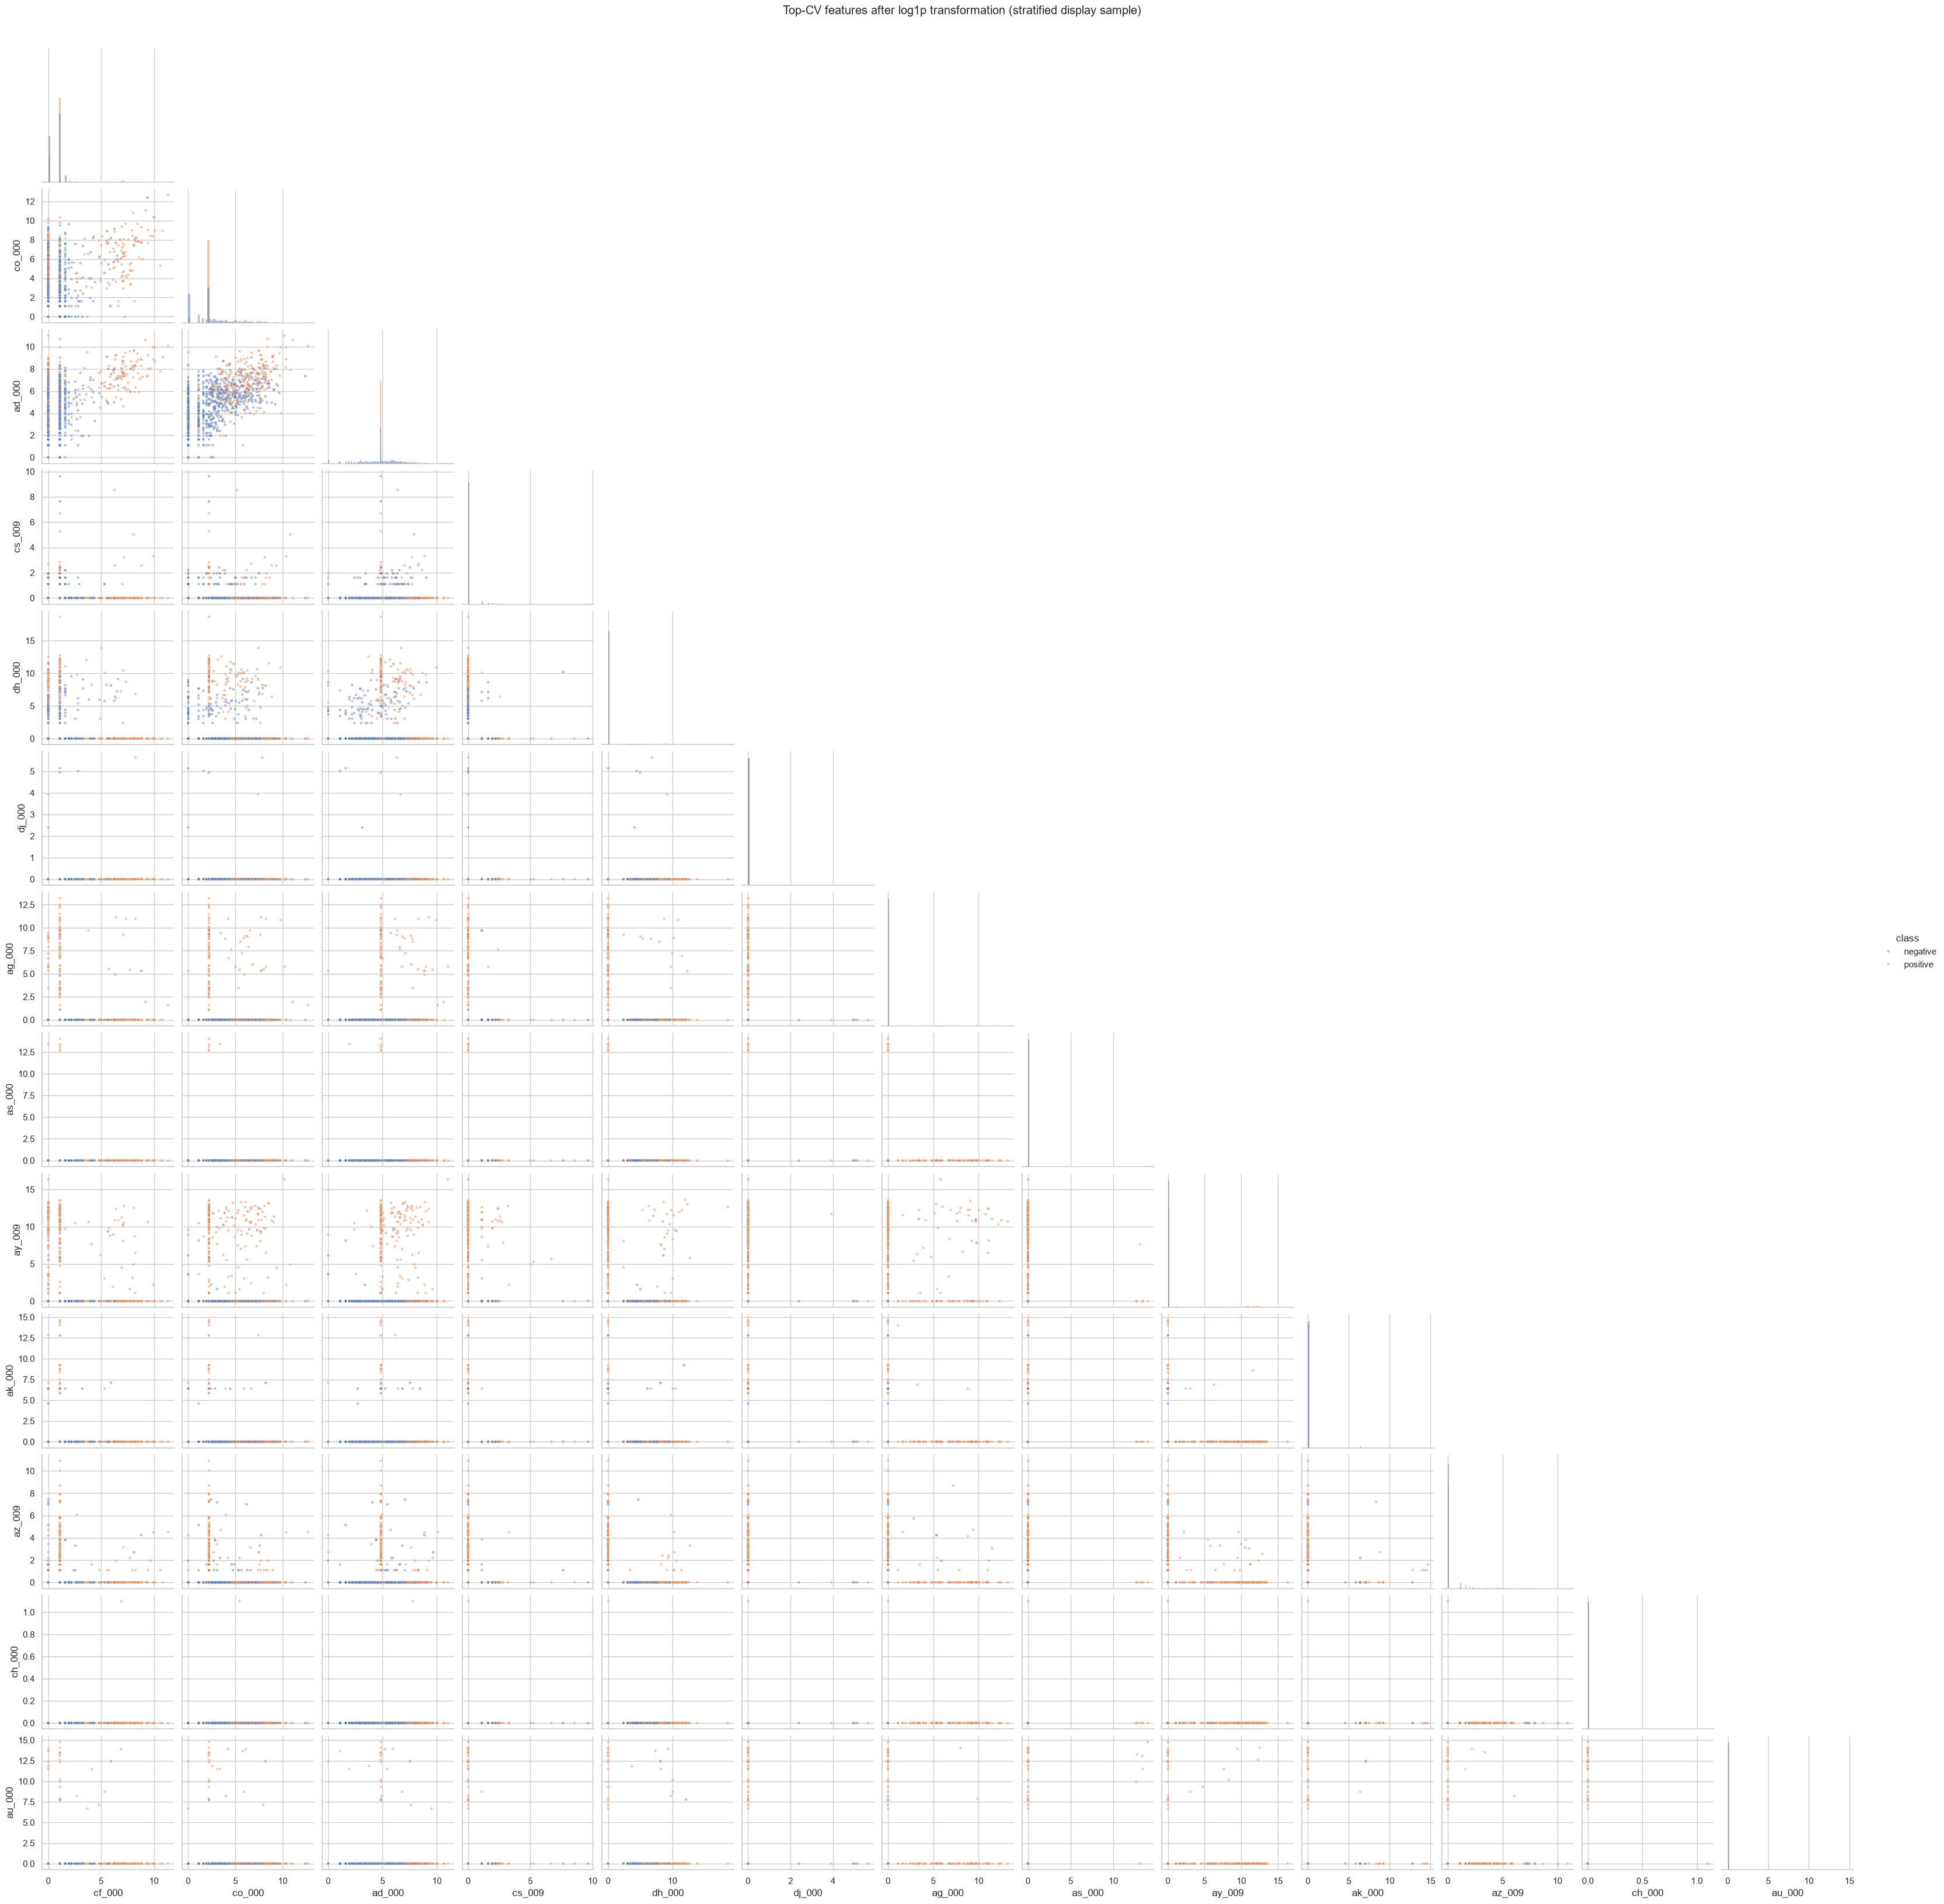

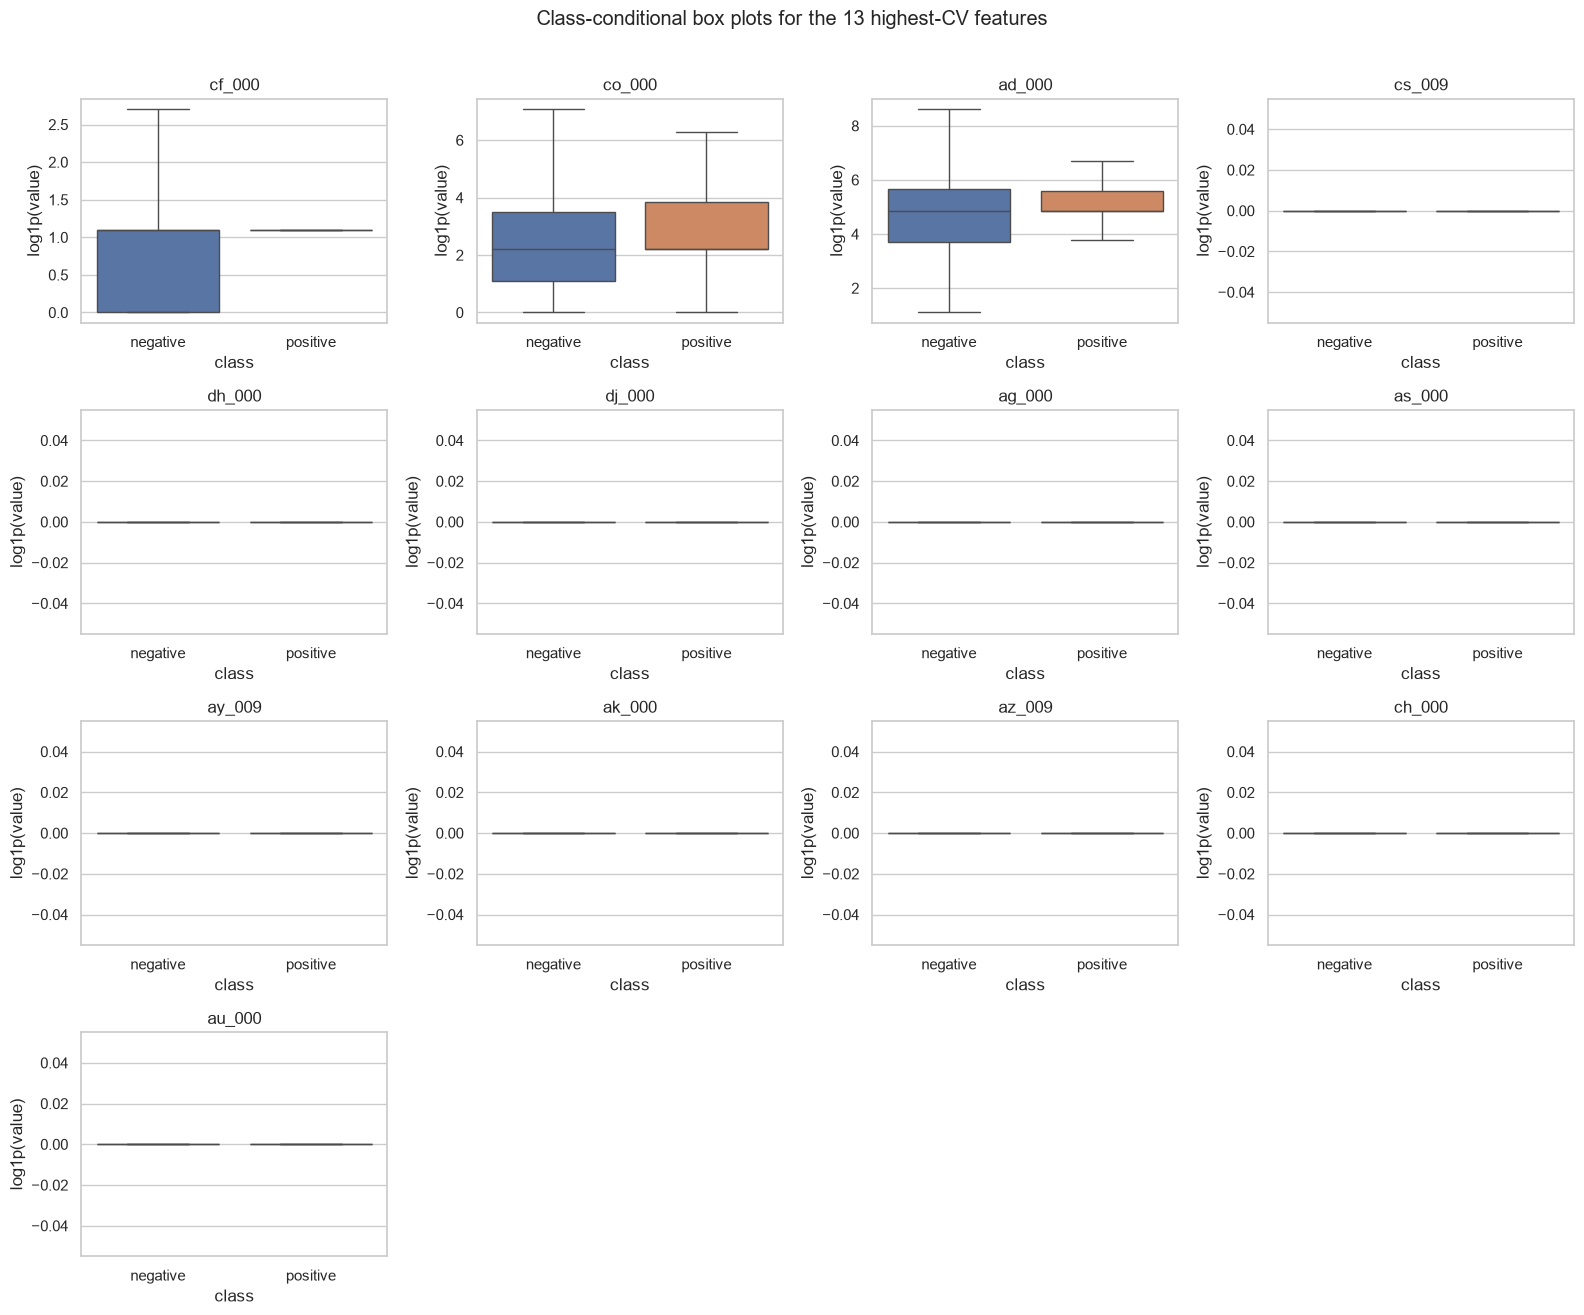

In [6]:
n_visual = int(np.floor(np.sqrt(len(feature_names))))
top_features = cv_table.dropna().head(n_visual).index.tolist()
print(f"sqrt({len(feature_names)}) = {np.sqrt(len(feature_names)):.3f}; using {n_visual} features:")
print(top_features)

# Quantify what the plots show. Because the APS columns are anonymized, their physical
# sensor meanings are unavailable; these statistics describe dispersion, separation,
# direction, and redundancy without inventing meanings for the feature names.
evidence_rows = []
for feature in top_features:
    x_log = np.log1p(X_train[feature].clip(lower=0))
    neg = x_log[y_train == 0]
    pos = x_log[y_train == 1]
    raw_auc = roc_auc_score(y_train, x_log)
    pooled_sd = np.sqrt(
        ((len(neg) - 1) * neg.var(ddof=1) + (len(pos) - 1) * pos.var(ddof=1))
        / (len(neg) + len(pos) - 2)
    )
    smd = (pos.mean() - neg.mean()) / pooled_sd if pooled_sd > 0 else np.nan
    max_abs_corr = corr.loc[feature].drop(feature).abs().max()
    evidence_rows.append({
        "feature": feature,
        "CV": cv_table.loc[feature, "CV"],
        "negative median log1p": neg.median(),
        "positive median log1p": pos.median(),
        "standardized mean difference": smd,
        "orientation-adjusted univariate AUC": max(raw_auc, 1 - raw_auc),
        "direction for positive class": "higher" if raw_auc >= 0.5 else "lower",
        "max absolute correlation with another feature": max_abs_corr,
    })

top_feature_evidence = pd.DataFrame(evidence_rows).set_index("feature")
display(top_feature_evidence.style.format({
    "CV": "{:.3f}",
    "negative median log1p": "{:.3f}",
    "positive median log1p": "{:.3f}",
    "standardized mean difference": "{:.3f}",
    "orientation-adjusted univariate AUC": "{:.3f}",
    "max absolute correlation with another feature": "{:.3f}",
}))

plot_df = X_train[top_features].copy()
plot_df["class"] = y_train.map({0: "negative", 1: "positive"})

# log1p makes the very skewed APS measurements visible. Use a stratified plotting sample
# for legibility while retaining every positive example.
neg_plot = plot_df[plot_df["class"] == "negative"].sample(n=1000, random_state=RANDOM_STATE)
pos_plot = plot_df[plot_df["class"] == "positive"]
pair_sample = pd.concat([neg_plot, pos_plot]).sample(frac=1, random_state=RANDOM_STATE)
pair_sample[top_features] = np.log1p(pair_sample[top_features].clip(lower=0))

g = sns.pairplot(pair_sample, vars=top_features, hue="class", corner=True,
                 plot_kws={"s": 10, "alpha": 0.45}, diag_kind="hist")
g.fig.suptitle("Top-CV features after log1p transformation (stratified display sample)", y=1.01)
plt.show()

long_box = X_train[top_features].copy()
long_box[top_features] = np.log1p(long_box[top_features].clip(lower=0))
long_box["class"] = y_train.map({0: "negative", 1: "positive"})
long_box = long_box.melt(id_vars="class", var_name="feature", value_name="log1p(value)")

fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, feature in zip(axes.flat, top_features):
    sns.boxplot(data=long_box[long_box["feature"] == feature], x="class", y="log1p(value)",
                hue="class", legend=False, showfliers=False, ax=ax)
    ax.set_title(feature)
for ax in axes.flat[len(top_features):]:
    ax.axis("off")
fig.suptitle("Class-conditional box plots for the 13 highest-CV features", y=1.01)
plt.tight_layout()
plt.show()

The feature names are anonymized APS sensor codes, so the data do not provide enough information to claim what physical quantity each one captures. Instead, the evidence table gives a defensible statistical interpretation:

- **CV** measures relative dispersion and is the criterion used to choose these 13 features; a large CV is not, by itself, evidence of class separation.
- The two **class medians** and the **standardized mean difference** quantify location separation after `log1p` reduces the influence of extreme right tails.
- The orientation-adjusted **univariate ROC AUC** measures how well one feature ranks positive versus negative cases; values near 0.5 are weak, while values farther from 0.5 show stronger separation. The direction column states whether positives tend to be higher or lower.
- The maximum absolute **correlation** indicates redundancy: a value near 1 means that another feature contains very similar linear information.

The numerical results show why CV alone is insufficient. `ay_009` and `ag_000` have the clearest mean shifts (standardized mean differences 2.456 and 1.484), while `ay_009` also has an orientation-adjusted AUC of 0.601. `cf_000`, `co_000`, and `ad_000` have modest AUCs of 0.584, 0.598, and 0.588, but each has a maximum absolute correlation of 1.000, indicating nearly duplicate linear information. In contrast, `cs_009`, `dj_000`, and `ch_000` have AUCs of only 0.502, 0.501, and 0.500: their very large CVs arise mainly from sparse extremes rather than useful marginal class separation. The equal zero medians for many features reinforce that sparsity. Therefore, the multivariate models below are needed to combine useful signals while handling redundancy and nonlinear interactions.

#### (v) Class balance

In [7]:
class_counts = pd.DataFrame({
    "train": y_train.value_counts().sort_index(),
    "test": y_test.value_counts().sort_index()
}, index=[0,1]).rename(index={0:"negative",1:"positive"})
class_counts["train_pct"] = class_counts["train"] / len(y_train) * 100
class_counts["test_pct"] = class_counts["test"] / len(y_test) * 100
display(class_counts.style.format({"train_pct":"{:.2f}%", "test_pct":"{:.2f}%"}))
print(f"Training imbalance ratio (negative:positive) = {(y_train==0).sum()/(y_train==1).sum():.1f}:1")

,train,test,train_pct,test_pct
negative,59000,15625,98.33%,97.66%
positive,1000,375,1.67%,2.34%


Training imbalance ratio (negative:positive) = 59.0:1


The positive class is rare, so accuracy alone can be misleading. I report confusion matrices, ROC/AUC, sensitivity, specificity, and the challenge cost in addition to overall error.

### Shared evaluation helper

In [8]:
def evaluate_classifier(model, Xtr, ytr, Xte, yte, title):
    tr_prob = model.predict_proba(Xtr)[:,1]
    te_prob = model.predict_proba(Xte)[:,1]
    tr_pred = (tr_prob >= 0.5).astype(int)
    te_pred = (te_prob >= 0.5).astype(int)
    rows = []
    fig, axes = plt.subplots(2, 2, figsize=(11, 9))
    for row, (split, y, pred, prob) in enumerate([
        ("train", ytr, tr_pred, tr_prob), ("test", yte, te_pred, te_prob)]):
        cm = confusion_matrix(y, pred, labels=[0,1])
        tn, fp, fn, tp = cm.ravel()
        auc = roc_auc_score(y, prob)
        fpr, tpr, _ = roc_curve(y, prob)
        ConfusionMatrixDisplay(cm, display_labels=["neg","pos"]).plot(ax=axes[row,0], colorbar=False)
        axes[row,0].set_title(f"{title}: {split} confusion matrix")
        axes[row,1].plot(fpr,tpr,label=f"AUC={auc:.4f}")
        axes[row,1].plot([0,1],[0,1],"--",color="gray")
        axes[row,1].set(xlabel="False-positive rate",ylabel="True-positive rate",
                        title=f"{title}: {split} ROC")
        axes[row,1].legend()
        rows.append({"split":split, "TN":tn,"FP":fp,"FN":fn,"TP":tp,
                     "misclassification":1-accuracy_score(y,pred), "AUC":auc,
                     "sensitivity":tp/(tp+fn), "specificity":tn/(tn+fp),
                     "challenge_cost":10*fp+500*fn})
    plt.tight_layout(); plt.show()
    result = pd.DataFrame(rows).set_index("split")
    display(result.style.format({"misclassification":"{:.4f}","AUC":"{:.4f}",
                                 "sensitivity":"{:.4f}","specificity":"{:.4f}"}))
    return result

### (c) Random forest without class-imbalance compensation

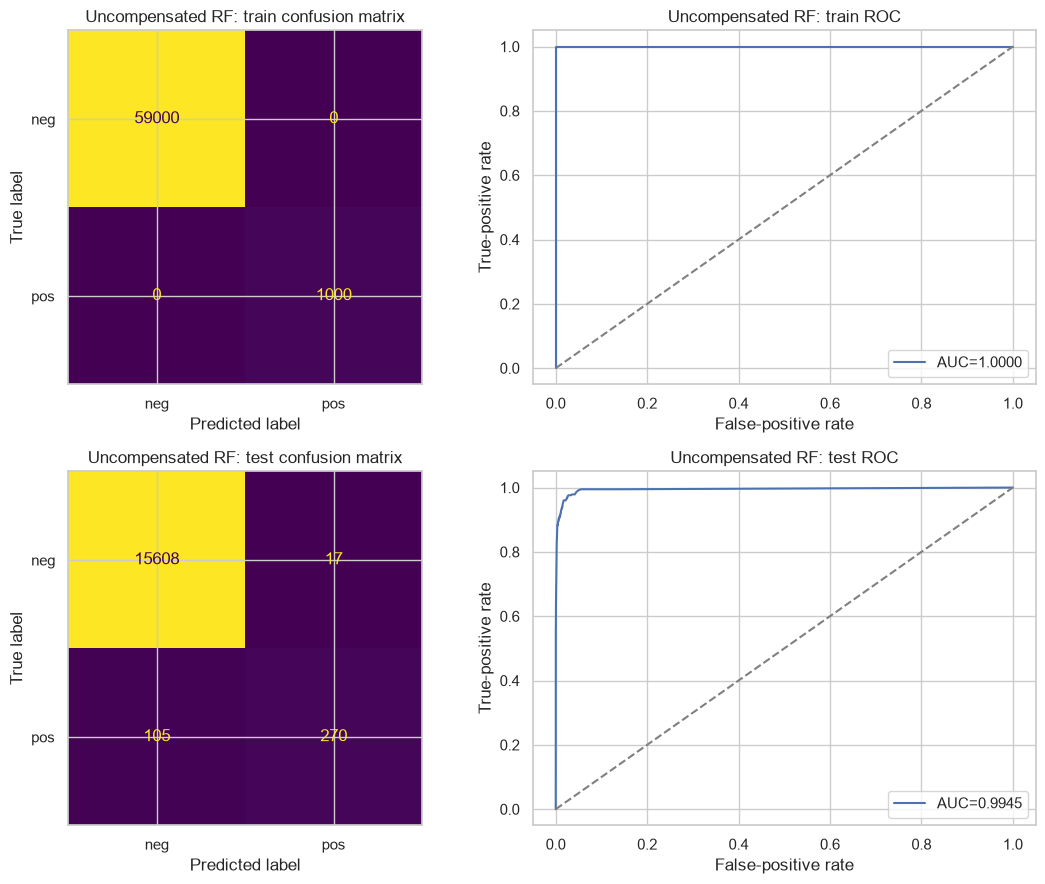

,TN,FP,FN,TP,misclassification,AUC,sensitivity,specificity,challenge_cost
split,,,,,,,,,
train,59000,0,0,1000,0.0000,1.0000,1.0000,1.0000,0
test,15608,17,105,270,0.0076,0.9945,0.7200,0.9989,52670


OOB error=0.0058; test error=0.0076; difference=-0.0019


In [9]:
rf_plain = RandomForestClassifier(n_estimators=300, max_features="sqrt", oob_score=True,
                                  random_state=RANDOM_STATE, n_jobs=N_JOBS)
rf_plain.fit(X_train, y_train)
rf_plain_metrics = evaluate_classifier(rf_plain, X_train, y_train, X_test, y_test,
                                       "Uncompensated RF")
rf_plain_oob_error = 1-rf_plain.oob_score_
print(f"OOB error={rf_plain_oob_error:.4f}; test error={rf_plain_metrics.loc['test','misclassification']:.4f}; "
      f"difference={rf_plain_oob_error-rf_plain_metrics.loc['test','misclassification']:+.4f}")

OOB error is an internal generalization estimate based on trees for which each observation was out-of-bag. It should be compared with, but need not exactly match, the independent test error.

### (d) Class-balanced random forest

Random forests can address imbalance through class-weighted split criteria, balanced bootstrap samples, threshold adjustment, or external resampling. Here I use `class_weight='balanced_subsample'`, which recomputes inverse-frequency class weights within each bootstrap sample.

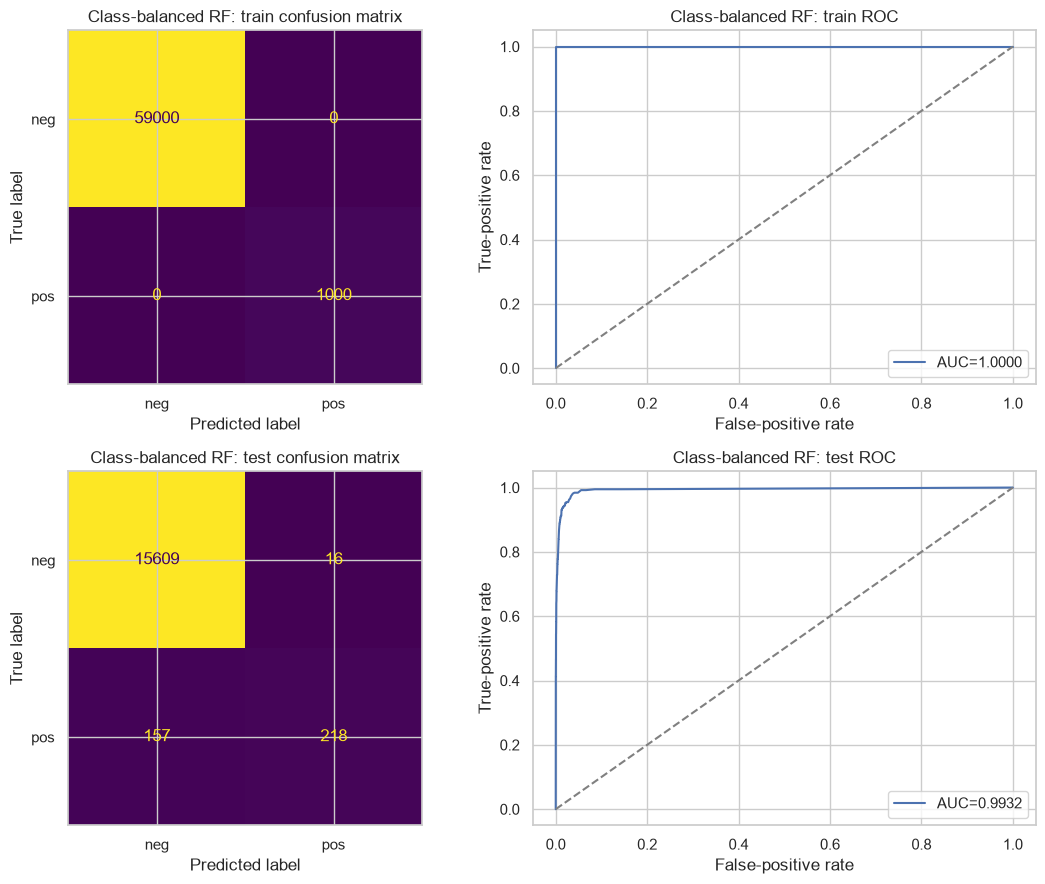

,TN,FP,FN,TP,misclassification,AUC,sensitivity,specificity,challenge_cost
split,,,,,,,,,
train,59000,0,0,1000,0.0000,1.0000,1.0000,1.0000,0
test,15609,16,157,218,0.0108,0.9932,0.5813,0.9990,78660


,OOB_error,misclassification,AUC,sensitivity,specificity,challenge_cost
model,,,,,,
uncompensated RF,0.0058,0.0076,0.9945,0.7200,0.9989,52670.000000
balanced RF,0.0078,0.0108,0.9932,0.5813,0.9990,78660.000000


In [10]:
rf_balanced = RandomForestClassifier(n_estimators=300, max_features="sqrt", oob_score=True,
                                     class_weight="balanced_subsample",
                                     random_state=RANDOM_STATE, n_jobs=N_JOBS)
rf_balanced.fit(X_train, y_train)
rf_bal_metrics = evaluate_classifier(rf_balanced, X_train, y_train, X_test, y_test,
                                     "Class-balanced RF")
rf_bal_oob_error = 1-rf_balanced.oob_score_

rf_comparison = pd.DataFrame([
    {"model":"uncompensated RF", "OOB_error":rf_plain_oob_error,
     **rf_plain_metrics.loc["test", ["misclassification","AUC","sensitivity","specificity","challenge_cost"]].to_dict()},
    {"model":"balanced RF", "OOB_error":rf_bal_oob_error,
     **rf_bal_metrics.loc["test", ["misclassification","AUC","sensitivity","specificity","challenge_cost"]].to_dict()},
]).set_index("model")
display(rf_comparison.style.format({c:"{:.4f}" for c in ["OOB_error","misclassification","AUC","sensitivity","specificity"]}))

In this run, `balanced_subsample` did **not** improve the random forest: test sensitivity fell from 0.7200 to 0.5813, test error rose from 0.0076 to 0.0108, and challenge cost rose from 52,670 to 78,660. Class weighting is a valid compensation method, but its effect is model- and threshold-dependent; the uncompensated forest performed better here.

### (e) XGBoost with L1 regularization

XGBoost uses the `binary:logistic` objective and applies L1 regularization (`reg_alpha`) to leaf weights. The L2 term is explicitly disabled with `reg_lambda=0`, so the grid genuinely isolates L1 regularization rather than approximating it with a large parameter value or mixing it with the default L2 penalty. I select `reg_alpha` by stratified cross-validation on the training set using ROC AUC, which is more informative than accuracy for this imbalanced response.

Minority-class training count = 1000; 3-fold stratified CV is valid.


,alpha,mean_test_roc_auc,std_test_roc_auc,mean_test_accuracy
0,0.000000,0.9899,0.0023,0.9940
1,0.100000,0.9892,0.0023,0.9940
2,1.000000,0.9896,0.0021,0.9937
3,10.000000,0.9895,0.0028,0.9927


Best alpha=0.0; 3-fold CV AUC=0.9899; CV misclassification=0.0060


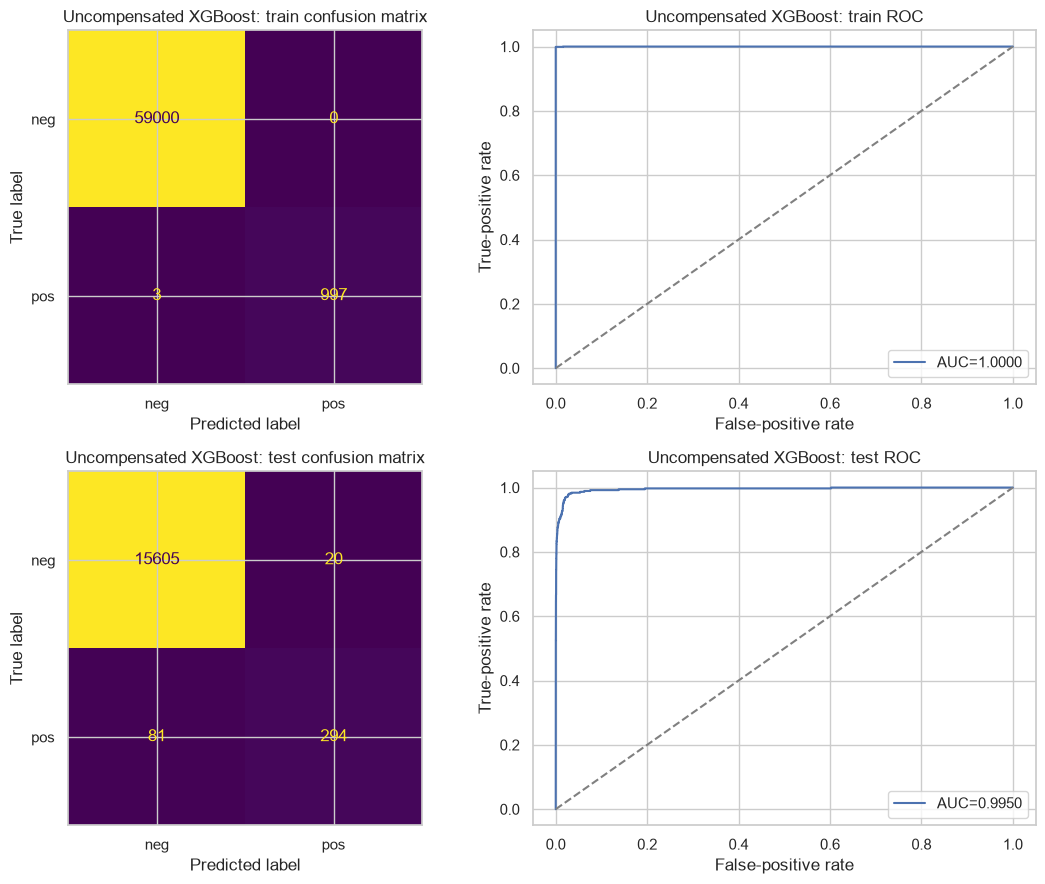

,TN,FP,FN,TP,misclassification,AUC,sensitivity,specificity,challenge_cost
split,,,,,,,,,
train,59000,0,3,997,0.0000,1.0000,0.9970,1.0000,1500
test,15605,20,81,294,0.0063,0.9950,0.7840,0.9987,40700


CV error=0.0060; test error=0.0063


In [11]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
minority_count = int(y_train.value_counts().min())
assert minority_count >= cv.n_splits
print(f"Minority-class training count = {minority_count}; {cv.n_splits}-fold stratified CV is valid.")
alpha_grid = [0.0, 0.1, 1.0, 10.0]

def make_xgb():
    return XGBClassifier(
        objective="binary:logistic", eval_metric="logloss", tree_method="hist",
        n_estimators=140, learning_rate=0.1, max_depth=6,
        min_child_weight=1, reg_lambda=0.0, subsample=0.85, colsample_bytree=0.85,
        random_state=RANDOM_STATE, n_jobs=N_JOBS
    )

xgb_pipe = SkPipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("xgb", make_xgb())
])
xgb_search = GridSearchCV(
    xgb_pipe, {"xgb__reg_alpha": alpha_grid}, cv=cv,
    scoring={"roc_auc":"roc_auc", "accuracy":"accuracy"}, refit="roc_auc",
    n_jobs=1, return_train_score=False
)
xgb_search.fit(X_train_raw, y_train)
xgb_cv = pd.DataFrame(xgb_search.cv_results_)[
    ["param_xgb__reg_alpha","mean_test_roc_auc","std_test_roc_auc","mean_test_accuracy"]
].rename(columns={"param_xgb__reg_alpha":"alpha"})
display(xgb_cv.style.format({"mean_test_roc_auc":"{:.4f}","std_test_roc_auc":"{:.4f}",
                             "mean_test_accuracy":"{:.4f}"}))
best_xgb = xgb_search.best_estimator_
best_xgb_cv_error = 1-xgb_search.cv_results_["mean_test_accuracy"][xgb_search.best_index_]
print(f"Best alpha={xgb_search.best_params_['xgb__reg_alpha']}; "
      f"3-fold CV AUC={xgb_search.best_score_:.4f}; CV misclassification={best_xgb_cv_error:.4f}")
xgb_metrics = evaluate_classifier(best_xgb, X_train_raw, y_train, X_test_raw, y_test,
                                  "Uncompensated XGBoost")
print(f"CV error={best_xgb_cv_error:.4f}; test error={xgb_metrics.loc['test','misclassification']:.4f}")

### (f) SMOTE followed by L1-regularized XGBoost

The correct cross-validation procedure places imputation and SMOTE inside the pipeline: each training fold is imputed and oversampled independently, while its validation fold remains untouched. This prevents data leakage. Three-fold stratified CV is valid here because the training set has 1,000 positive observations—far more than the three folds—and the notebook prints and asserts this condition above. The same folds and ROC-AUC selection rule are used for a fair comparison.

,alpha,mean_test_roc_auc,std_test_roc_auc,mean_test_accuracy
0,0.000000,0.9889,0.0031,0.9926
1,0.100000,0.9889,0.0030,0.9927
2,1.000000,0.9886,0.0032,0.9925
3,10.000000,0.9885,0.0025,0.9908


Best alpha=0.0; 3-fold CV AUC=0.9889; CV misclassification=0.0074


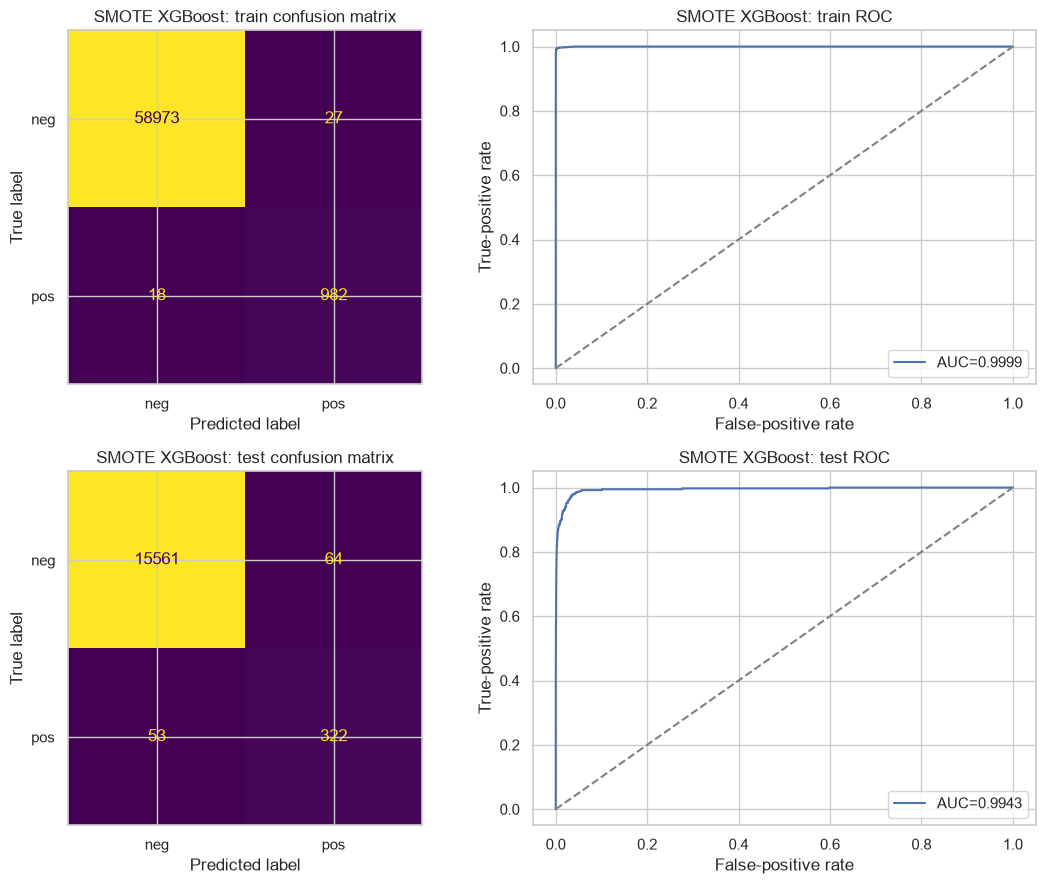

,TN,FP,FN,TP,misclassification,AUC,sensitivity,specificity,challenge_cost
split,,,,,,,,,
train,58973,27,18,982,0.0008,0.9999,0.9820,0.9995,9270
test,15561,64,53,322,0.0073,0.9943,0.8587,0.9959,27140


,CV_error,misclassification,AUC,sensitivity,specificity,challenge_cost
model,,,,,,
uncompensated XGBoost,0.0060,0.0063,0.9950,0.7840,0.9987,40700.000000
SMOTE XGBoost,0.0074,0.0073,0.9943,0.8587,0.9959,27140.000000


In [12]:
smote_xgb_pipe = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
    ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=5)),
    ("xgb", make_xgb())
])
smote_search = GridSearchCV(
    smote_xgb_pipe, {"xgb__reg_alpha": alpha_grid}, cv=cv,
    scoring={"roc_auc":"roc_auc", "accuracy":"accuracy"}, refit="roc_auc",
    n_jobs=1, return_train_score=False
)
smote_search.fit(X_train_raw, y_train)
smote_cv = pd.DataFrame(smote_search.cv_results_)[
    ["param_xgb__reg_alpha","mean_test_roc_auc","std_test_roc_auc","mean_test_accuracy"]
].rename(columns={"param_xgb__reg_alpha":"alpha"})
display(smote_cv.style.format({"mean_test_roc_auc":"{:.4f}","std_test_roc_auc":"{:.4f}",
                               "mean_test_accuracy":"{:.4f}"}))
best_smote_xgb = smote_search.best_estimator_
smote_cv_error = 1-smote_search.cv_results_["mean_test_accuracy"][smote_search.best_index_]
print(f"Best alpha={smote_search.best_params_['xgb__reg_alpha']}; "
      f"3-fold CV AUC={smote_search.best_score_:.4f}; CV misclassification={smote_cv_error:.4f}")
smote_metrics = evaluate_classifier(best_smote_xgb, X_train_raw, y_train, X_test_raw, y_test,
                                    "SMOTE XGBoost")

xgb_comparison = pd.DataFrame([
    {"model":"uncompensated XGBoost", "CV_error":best_xgb_cv_error,
     **xgb_metrics.loc["test", ["misclassification","AUC","sensitivity","specificity","challenge_cost"]].to_dict()},
    {"model":"SMOTE XGBoost", "CV_error":smote_cv_error,
     **smote_metrics.loc["test", ["misclassification","AUC","sensitivity","specificity","challenge_cost"]].to_dict()},
]).set_index("model")
display(xgb_comparison.style.format({c:"{:.4f}" for c in ["CV_error","misclassification","AUC","sensitivity","specificity"]}))

SMOTE is applied to the entire training set when the final best pipeline is refit, satisfying the assignment requirement while keeping validation folds uncontaminated during model selection. With L2 disabled, cross-validation selected `reg_alpha=0` for both models; this means the unregularized end of the tested L1 grid performed best, not that a default L2 penalty was used. On the test set, SMOTE increased sensitivity from **0.7840** to **0.8587** and reduced challenge cost from **40,700** to **27,140**, at the expense of higher misclassification (**0.0073** vs **0.0063**), lower specificity (**0.9959** vs **0.9987**), and slightly lower AUC (**0.9943** vs **0.9950**). The ROC curves and AUC values above are reported for both training and test sets for both XGBoost models.

## 2. ISLR 6.6.3

The constraint is the lasso constraint `sum(|beta_j|) <= s`. Increasing `s` loosens the constraint and makes the model more flexible.

- **(a) Training RSS: iv, steadily decreases.** A larger feasible set cannot make the optimal training RSS worse.
- **(b) Test RSS: ii, decreases initially and then increases (U-shape).** Flexibility first reduces bias, but eventually variance and overfitting dominate.
- **(c) Variance: iii, steadily increases.** Coefficients are less constrained and respond more strongly to training-sample variation.
- **(d) Squared bias: iv, steadily decreases.** The model can represent a larger set of relationships.
- **(e) Irreducible error: v, remains constant.** It is a property of the data-generating noise, not model flexibility.

## 3. ISLR 6.6.5

Let `x11=x12=a`, `x21=x22=-a`, `y1=y`, and `y2=-y`, which follows from the centering assumptions.

**(a)** The ridge objective is

`2[y - a(beta1+beta2)]^2 + lambda(beta1^2+beta2^2)`.

**(b)** The data-fit term depends only on `beta1+beta2`. For a fixed sum `t`, the penalty `beta1^2+beta2^2` is minimized at `beta1=beta2=t/2`. Equivalently, subtracting the two first-order conditions gives `2 lambda (beta1-beta2)=0`. Hence the ridge estimates satisfy `beta1=beta2`.

**(c)** The lasso objective is

`2[y - a(beta1+beta2)]^2 + lambda(|beta1|+|beta2|)`.

**(d)** Again the fit depends only on `t=beta1+beta2`. If the optimal `t>0`, every pair with `beta1>=0`, `beta2>=0`, and `beta1+beta2=t` has the same fit and penalty `lambda*t`; if `t<0`, the analogous set has both coefficients non-positive. Thus the lasso can distribute the total coefficient arbitrarily among identical predictors, so the individual coefficients are not unique (except in the degenerate `t=0` case).

## 4. ISLR 8.4.5

Using a 0.5 cutoff, six trees predict Red and four predict Green, so **majority vote predicts Red**.

The average estimated red probability is

`(0.10+0.15+0.20+0.20+0.55+0.60+0.60+0.65+0.70+0.75)/10 = 0.45`.

Since `0.45 < 0.5`, **averaging probabilities predicts Green**. The two aggregation rules therefore disagree.

## 5. ISLR 9.7.3

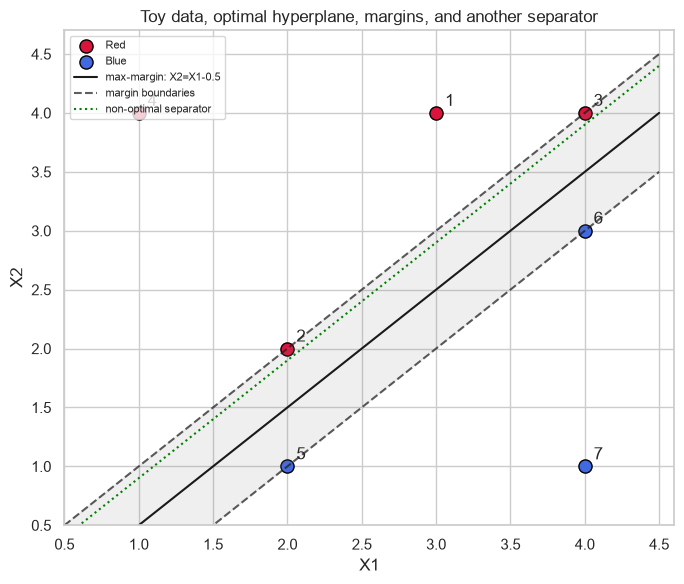

In [13]:
toy = pd.DataFrame({
    "X1":[3,2,4,1,2,4,4], "X2":[4,2,4,4,1,3,1],
    "class":["Red"]*4+["Blue"]*3, "obs":range(1,8)
})
fig, ax = plt.subplots(figsize=(7,6))
for cls, color in [("Red","crimson"),("Blue","royalblue")]:
    d = toy[toy["class"]==cls]
    ax.scatter(d.X1,d.X2,c=color,s=90,label=cls,edgecolor="black")
for _,r in toy.iterrows(): ax.annotate(str(r.obs),(r.X1+.06,r.X2+.06))
x = np.linspace(.5,4.5,200)
ax.plot(x, x-.5, "k-", label="max-margin: X2=X1-0.5")
ax.plot(x, x, "k--", alpha=.7, label="margin boundaries")
ax.plot(x, x-1, "k--", alpha=.7)
ax.plot(x, x-.1, color="green", linestyle=":", label="non-optimal separator")
ax.fill_between(x,x-1,x,color="gray",alpha=.12)
ax.set(xlim=(.5,4.6),ylim=(.5,4.7),xlabel="X1",ylabel="X2",
       title="Toy data, optimal hyperplane, margins, and another separator")
ax.legend(loc="upper left",fontsize=8); plt.tight_layout(); plt.show()

**(a)** The plot shows all seven labeled observations.

**(b)** The optimal separating hyperplane lies midway between the nearest parallel class boundaries `X2-X1=0` (Red) and `X2-X1=-1` (Blue):

`0.5 - X1 + X2 = 0`, or `X2 = X1 - 0.5`.

**(c)** Classify as **Red** if `0.5 - X1 + X2 > 0`, and as **Blue** otherwise. Thus `beta0=0.5`, `beta1=-1`, and `beta2=1`.

**(d)** The margin boundaries are `X2=X1` and `X2=X1-1`. Each is `0.5/sqrt(2)` from the hyperplane, so the full margin width is `1/sqrt(2)`.

**(e)** The support vectors are observations **2 `(2,2)`**, **3 `(4,4)`**, **5 `(2,1)`**, and **6 `(4,3)`**.

**(f)** Observation 7 `(4,1)` lies well inside the Blue side and is not a support vector. A slight movement that does not reach a margin boundary leaves the active constraints, and therefore the maximal-margin hyperplane, unchanged.

**(g)** One non-optimal separating hyperplane is `0.1-X1+X2=0` (`X2=X1-0.1`). It separates the classes but is not centered between the closest observations, so its minimum margin is smaller.

**(h)** Adding a Blue observation at `(3,4)`, the same location as Red observation 1, makes linear separation impossible. More generally, placing a Blue point inside the convex hull of the Red points would also destroy separability.

## Reproducibility summary

In [14]:
print("Random state:", RANDOM_STATE)
print("Training/test shapes:", train_df.shape, test_df.shape)
print("RF OOB errors (plain, balanced):", round(rf_plain_oob_error,5), round(rf_bal_oob_error,5))
print("Best XGBoost alpha:", xgb_search.best_params_["xgb__reg_alpha"])
print("Best SMOTE-XGBoost alpha:", smote_search.best_params_["xgb__reg_alpha"])

Random state: 552
Training/test shapes: (60000, 171) (16000, 171)
RF OOB errors (plain, balanced): 0.00575 0.00775
Best XGBoost alpha: 0.0
Best SMOTE-XGBoost alpha: 0.0
